# 01 - Data audit

We inspect the workbook before touching it. The checks follow the brief: missing values, duplicates,
duplicate columns, outliers, invalid codes, class balance, logical consistency and availability.
Nothing is changed in this notebook; corrections happen in `src/preprocessing.py` and are logged.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
from src import data_validation as V
raw = V.load_raw()
print(raw.shape)
raw.head()

(531, 38)


,ID,Distance_km,Trip_Purpose,Income,Gender,Age,Education,Occup,ParkingSpace,walk_time_min,TwoW_time_min,auto_time_min,car_time_min,local_train_time_min,bus_time_min,Area_Type,Dwelling,HH_Size,Adults,Children,Working_Adults,SAPT,Choice,DL_TwoW,DL_Car,Car_AV,TwoW_AV,Walk_AV,Auto_AV,Bus_AV,LocalTrain_AV,Car_Ownership,TwoW_Ownership,TC_Car,TC_2W,TC_Auto,TC_Bus,TC_LocalTrain
0,1,2.5,2,1,1,2,2,3,0,37.5,6.0,7.5,6.8,4.3,8.8,0,4,6,4,2,1,1,3,0,0,0,0,0,1,0,1,0,0,11,4,24,7,5
1,2,2.5,2,1,1,1,2,5,0,37.5,6.0,7.5,6.8,4.3,8.8,0,4,2,2,0,1,1,2,1,0,0,1,0,0,0,1,1,1,11,4,24,7,5
2,3,20.5,2,3,1,2,1,3,0,306.9,49.1,61.4,55.8,35.1,72.2,1,1,6,5,1,1,1,4,1,1,1,1,0,1,0,1,1,1,91,33,201,30,10
3,4,19.3,2,1,1,2,2,3,0,288.8,46.2,57.8,52.5,33.0,67.9,0,4,4,2,2,1,1,4,1,1,1,1,0,0,0,1,1,1,86,31,189,29,5
4,8,1.2,2,1,1,2,2,5,0,18.2,2.9,3.6,3.3,2.1,4.3,0,4,5,2,3,1,1,3,1,0,0,1,1,1,0,1,0,1,5,2,15,7,5


In [2]:
audit = V.run_audit(raw)
for k in ["missing_values", "duplicate_rows", "duplicate_rows_ignoring_id", "id_unique", "id_range",
          "duplicate_columns", "constant_columns", "target_counts"]:
    print(f"{k:28s}", audit[k])

missing_values               0
duplicate_rows               0
duplicate_rows_ignoring_id   0
id_unique                    True
id_range                     (1, 654)
duplicate_columns            [('DL_TwoW', 'TwoW_AV'), ('DL_Car', 'Car_AV')]
constant_columns             ['LocalTrain_AV']
target_counts                {'Walk': 47, 'Two-wheeler': 142, 'Auto-rickshaw': 34, 'Car': 131, 'Bus': 56, 'Suburban rail': 121}


No values are missing and no record is duplicated. IDs are unique but run from 1 to 654, so 123
IDs are absent; presumably records were removed before the file reached us. `DL_TwoW` and `DL_Car`
are exact copies of `TwoW_AV` and `Car_AV`, and `LocalTrain_AV` equals 1 for all 531 people.

The target is imbalanced: auto-rickshaw (34) and walking (47) are the two smallest classes.

## Coding scheme against `Data Coding.docx`

In [3]:
audit["code_check"]

,variable,documented_codes,observed_counts,undocumented_codes_in_data,documented_but_unused,consistent
0,Age,"1=18-30, 2=30-55, 3=>55","1:33, 2:365, 3:133",[],[],True
1,Education,"1=Graduation, 2=SSC/Diploma, 3=Below SSC","1:292, 2:182, 3:57",[],[],True
2,Occup,"1=Unemployed, 2=Government employee, 3=Service, 4=Self-employed","1:3, 2:135, 3:234, 4:4, 5:155",[5],[],False
3,Income,"1=<30,000, 2=30,000-80,000, 3=>80,000","1:213, 2:243, 3:75",[],[],True
4,Dwelling,"1=Apartment, 2=Independent house, 3=Row house","1:186, 2:10, 3:144, 4:191",[4],[],False
5,SAPT,"0=Not satisfied, 1=Satisfied","0:29, 1:502",[],[],True
6,Trip_Purpose,"0=Non-work, 1=Work","1:106, 2:425",[2],[0],False
7,Choice,"1=Walk, 2=Two-wheeler, 3=Auto-rickshaw, 4=Car, 5=Bus, 6=Suburban rail","1:47, 2:142, 3:34, 4:131, 5:56, 6:121",[],[],True


Three variables disagree with the coding document:

* **Trip_Purpose** is coded 1/2 in the data but 0/1 in the document.
* **Occup** has a fifth code (5, 155 records) that the document does not list.
* **Dwelling** has a fourth code (4, 191 records) that the document does not list.

Gender, Area_Type and ParkingSpace are not in the document at all. We do not relabel anything. The
cross-tabulations below are the evidence we have; they suggest, but do not prove, how some codes
should be read.

In [4]:
ev = audit["category_evidence"]
display(ev["purpose_by_age"]); display(ev["purpose_by_occupation"]); display(ev["occupation_by_age"])

Trip_Purpose,1,2
Age,,
1,0,33
2,35,330
3,71,62


Trip_Purpose,1,2
Occup,,
1,0,3
2,72,63
3,13,221
4,3,1
5,18,137


Age,1,2,3
Occup,,,
1,3,0,0
2,0,48,87
3,20,191,23
4,0,0,4
5,10,126,19


All 33 respondents aged 18-30 report purpose code 2, as do 94% of occupation code 3, while purpose
code 1 is concentrated among people over 55. That pattern fits "2 = work trip, 1 = non-work trip",
the document's 0/1 shifted by one, but nobody has confirmed it. The occupation evidence is more
worrying: code 2, labelled "Government employee", is 64% aged over 55 and makes mostly purpose-1
trips, and code 1 ("Unemployed") only makes purpose-2 trips. The document's occupation labels may
simply not apply to this file. We keep neutral labels ("occupation code 2") everywhere.

## Travel times and costs are computed from distance

In [5]:
rules = audit["los_rules"]
print(json.dumps({k: v for k, v in rules.to_dict().items() if k not in ("bus_fare_steps",)}, indent=1))

{
 "time_rate_min_per_km": {
  "walk": 15.0,
  "twow": 2.4,
  "auto": 3.0,
  "car": 2.7273,
  "bus": 3.5294,
  "train": 1.7143
 },
 "implied_speed_kmh": {
  "walk": 4.0,
  "twow": 25.0,
  "auto": 20.0,
  "car": 22.0,
  "bus": 17.0,
  "train": 35.0
 },
 "car_rate_inr_per_km": 4.4482,
 "twow_rate_inr_per_km": 1.6043,
 "auto_fare": {
  "minimum": 15.0,
  "slope": 9.8682,
  "intercept": -0.7673
 },
 "train_fare_steps": [
  [
   19.75,
   5.0
  ],
  [
   39.15,
   10.0
  ],
  [
   68.35,
   15.0
  ],
  [
   "inf",
   25.0
  ]
 ]
}


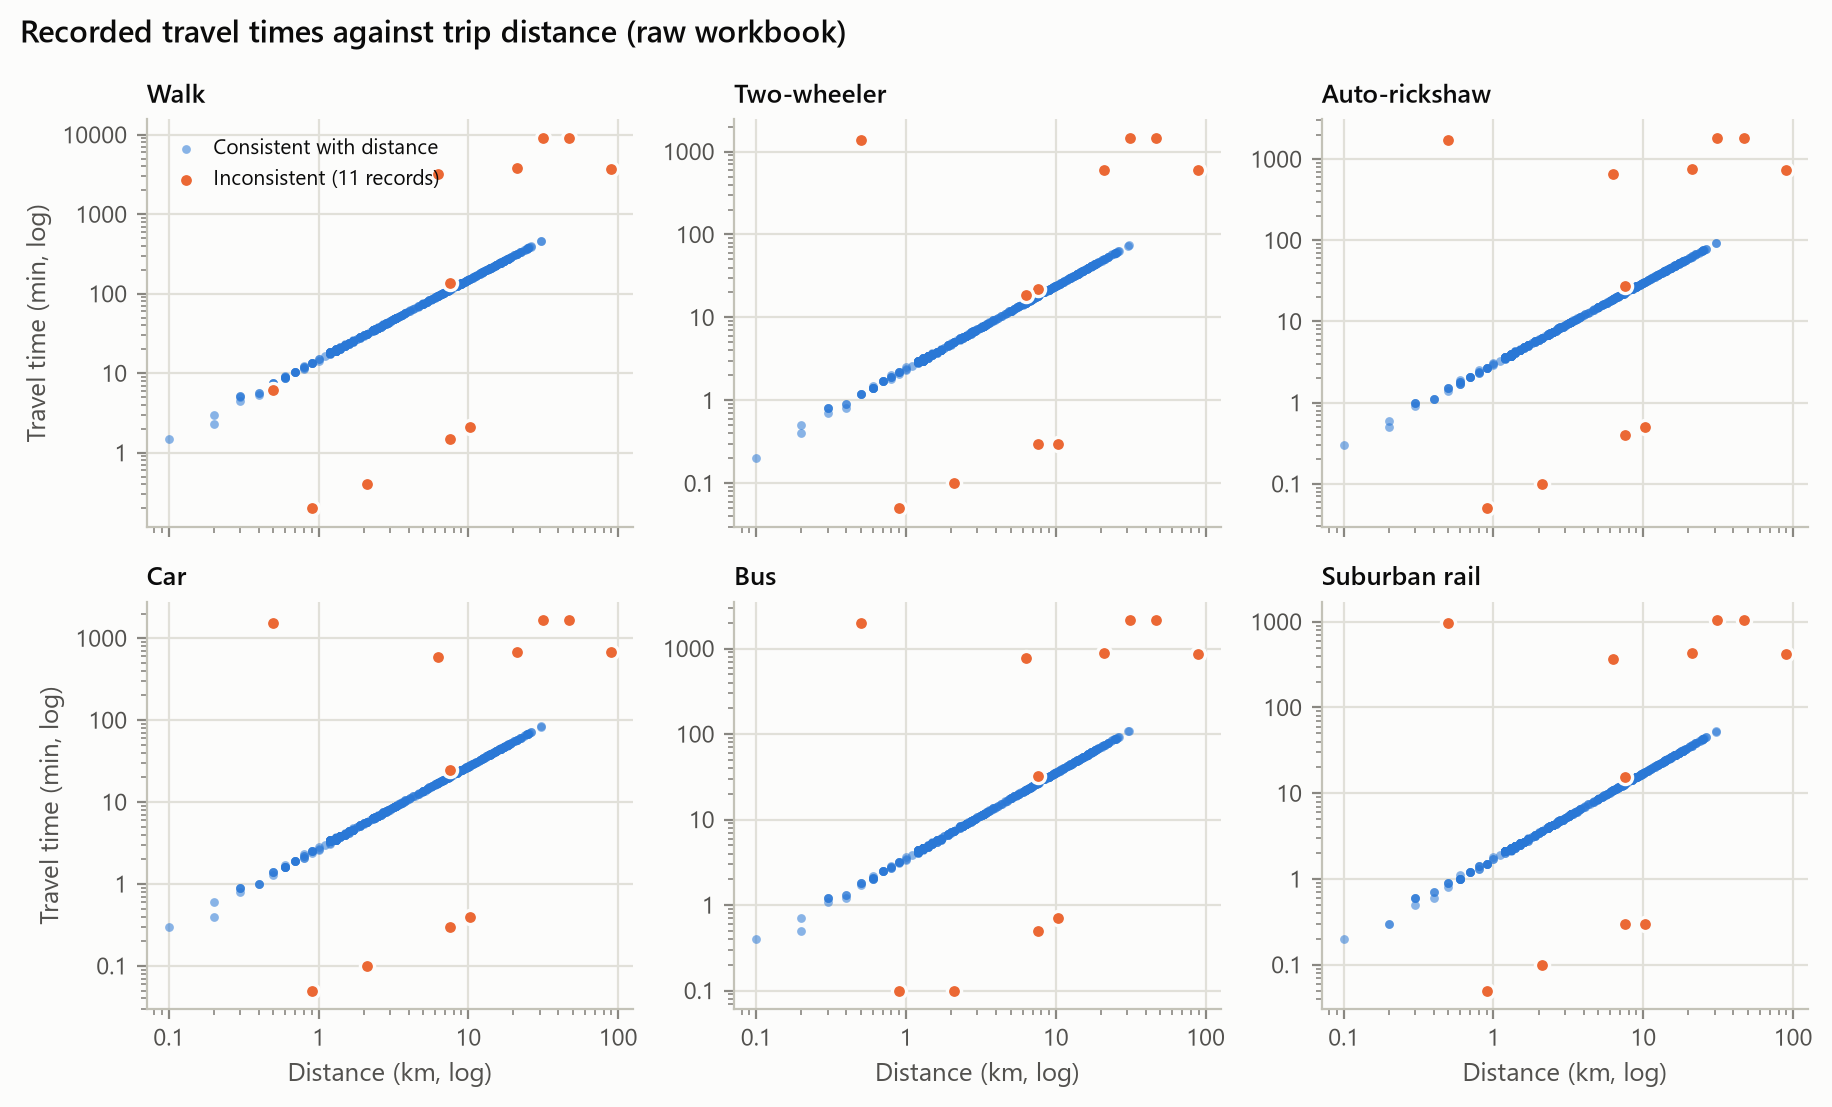

In [6]:
fig("audit_time_vs_distance.png")

Every travel time equals distance multiplied by a fixed rate, to rounding: walking at 4 km/h,
two-wheeler 25, auto 20, car 22, bus 17 and rail 35 km/h. Costs follow a per-km rate (car INR 4.45,
two-wheeler INR 1.60), an auto fare of max(15, 9.87 d - 0.74), and stepped bus and rail fare tables.
So the level-of-service attributes were generated from distance, not observed for each trip. This
matters a lot later: no model can learn a separate effect of bus travel time, because in these data
bus time is just distance times 3.53.

Eleven records break the rule:

In [7]:
display(audit["los_inconsistent"])
display(audit["cost_rule_match"])

,ID,Distance_km,km_implied_by_walk_time,km_implied_by_twow_time,km_implied_by_auto_time,km_implied_by_car_time,km_implied_by_bus_time,km_implied_by_train_time,km_implied_by_car_cost,km_implied_by_2w_cost
0,179,0.5,0.41,566.50,566.50,566.50,566.50,566.48,0.45,0.62
1,273,7.6,0.10,0.12,0.13,0.11,0.14,0.18,7.64,7.48
2,275,7.6,9.10,9.08,9.10,9.09,9.10,9.10,7.64,7.48
3,278,0.9,0.01,0.00,0.00,0.00,0.03,0.00,0.90,0.62
4,283,10.3,0.14,0.12,0.17,0.15,0.20,0.18,10.34,10.60
5,326,2.1,0.03,0.04,0.03,0.04,0.03,0.06,2.02,1.87
6,403,6.3,217.01,7.83,217.00,217.03,217.00,217.00,6.29,6.23
7,482,31.3,607.70,607.71,607.70,607.71,607.69,607.72,31.25,31.17
8,525,89.7,247.52,247.54,247.53,247.54,247.52,247.51,89.70,89.76
9,533,21.1,251.07,251.08,251.07,251.06,251.06,251.07,21.13,21.19


,cost_column,exact_match_share,within_1_inr_share,max_abs_diff_inr
0,TC_Car,0.906,1.0,1.0
1,TC_2W,0.962,1.0,1.0
2,TC_Auto,0.942,1.0,1.0
3,TC_Bus,0.996,1.0,1.0
4,TC_LocalTrain,1.000,1.0,0.0


For all eleven, the car and two-wheeler costs imply the recorded distance, while the times imply
distances that are off by large factors (ID 179's motorised times are exactly 1,000 times too large,
the pattern of metres typed as kilometres). The distance is therefore right and the times are wrong.
`preprocessing.clean_data` recomputes the six times of these records from distance and logs every
change. Extreme distances themselves (up to 89.7 km) agree with their costs and are kept.

## Availability

In [8]:
audit["availability"]

{'chosen_alternative_unavailable': 0,
 'availability_share': {'walk': 0.482,
  'twow': 0.729,
  'auto': 0.667,
  'car': 0.552,
  'bus': 0.179,
  'train': 1.0},
 'n_available_alternatives': {1: 8, 2: 79, 3: 166, 4: 153, 5: 110, 6: 15},
 'single_alternative_records': 8,
 'car_av_without_car': 0,
 'twow_av_without_twow': 0,
 'car_owned_but_unavailable': 60,
 'twow_owned_but_unavailable': 47,
 'walk_av_share_up_to_1.5km': 1.0,
 'walk_av_share_above_3km': 0.293,
 'max_walk_distance_chosen_km': 3.6}

No respondent chose an unavailable mode. Bus is available to only 18% of respondents but chosen by
59% of them, which hints that bus availability may have been recorded with the chosen mode in mind;
we note this as a limitation. Car availability equals licence holding among car-owning households;
60 people live in car-owning households but have no car available.

## Household consistency and outliers

In [9]:
print(audit["household_flag_counts"])
hh = audit["household_flags"]
raw.loc[hh.drop(columns="ID").any(axis=1).to_numpy(), ["ID", "HH_Size", "Adults", "Children", "Working_Adults"]]

{'hh_size_not_adults_plus_children': 3, 'zero_adults': 1, 'workers_exceed_adults': 15, 'workers_exceed_hh_size': 3}


,ID,HH_Size,Adults,Children,Working_Adults
12,16,3,2,1,3
22,32,5,2,3,3
23,33,4,4,1,2
24,35,5,7,2,1
25,36,4,5,2,3
26,37,5,2,3,3
49,69,5,0,5,1
54,74,5,1,4,2
57,77,7,2,5,4
58,78,5,2,3,3


Fifteen households report more workers than adults. That is possible if "Children" counts sons
and daughters of any age rather than minors, so we flag these records rather than editing them.
Three records have HH_Size different from Adults + Children and three have more workers than
members; the derived workers-share feature caps workers at household size.

In [10]:
audit["outliers"]

,column,min,median,max,q3_plus_3iqr,n_above_q3_plus_3iqr,n_zero
0,Distance_km,0.1,3.8,89.7,36.2,2,0
1,walk_time_min,0.2,54.3,9115.5,543.0,5,0
2,TwoW_time_min,0.0,8.9,1458.5,87.0,5,1
3,auto_time_min,0.0,11.1,1823.1,109.4,6,1
4,car_time_min,0.0,10.1,1657.4,99.4,6,1
5,bus_time_min,0.1,13.1,2144.8,128.7,6,0
6,local_train_time_min,0.0,6.3,1041.8,62.7,6,1
7,TC_2W,0.0,6.0,144.0,57.0,2,4
8,TC_Auto,15.0,37.0,885.0,357.0,2,0
9,TC_Car,0.0,17.0,399.0,161.0,2,1


## Verified data dictionary

In [11]:
dd = V.build_data_dictionary(raw)
dd[["variable", "type", "documented_coding", "observed_values", "status", "treatment"]]

,variable,type,documented_coding,observed_values,status,treatment
0,ID,identifier,not in coding document,"min 1, median 330, max 654",OK,Kept as is.
1,Distance_km,continuous,not in coding document,"min 0.1, median 3.8, max 89.7",OK,Kept as is.
2,Trip_Purpose,binary,"0=Non-work, 1=Work","1:106, 2:425",DISCREPANCY,Kept as code 1 / code 2 (neutral labels). Not remapped.
3,Income,ordinal,"1=<30,000, 2=30,000-80,000, 3=>80,000","1:213, 2:243, 3:75",OK,Kept as is.
4,Gender,binary,not in coding document,"0:16, 1:515",UNDOCUMENTED,Kept as binary code; too few code-0 records to estimate a gender effect in t...
5,Age,ordinal,"1=18-30, 2=30-55, 3=>55","1:33, 2:365, 3:133",OK,Kept as is.
6,Education,ordinal,"1=Graduation, 2=SSC/Diploma, 3=Below SSC","1:292, 2:182, 3:57",OK,Kept as is.
7,Occup,nominal,"1=Unemployed, 2=Government employee, 3=Service, 4=Self-employed","1:3, 2:135, 3:234, 4:4, 5:155",DISCREPANCY,Kept as nominal codes; codes 1 and 4 (3 and 4 records) pooled as 'rare' for ...
8,ParkingSpace,binary,not in coding document,"0:348, 1:183",UNDOCUMENTED,Kept as binary code.
9,walk_time_min,continuous,not in coding document,"min 0.2, median 54.3, max 9115.5",DERIVED + ERRORS,11 records recomputed from distance (logged).


**Open questions for the data owner:** (1) the meaning of Trip_Purpose codes 1 and 2; (2) the labels
of occupation codes 1-5, in particular code 5; (3) the label of dwelling code 4; (4) the coding of
Gender, Area_Type and ParkingSpace (home or destination parking?); (5) whether "Children" means minors;
(6) how mode availability was determined.